In [12]:
# Assignment 3
# Forward Propagation and Backpropagation using TensorFlow/Keras
# Analyze the effect of different learning rates and epochs

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf


In [13]:
# Load Iris Dataset

iris = load_iris()

X = iris.data
y = iris.target

In [14]:
# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
# Feature Scaling

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [16]:
# Function to Create Model

def create_model(learning_rate):

    model = tf.keras.Sequential([
        tf.keras.layers.Dense(16, activation='relu', input_shape=(4,)),
        tf.keras.layers.Dense(8, activation='relu'),
        tf.keras.layers.Dense(3, activation='softmax')
    ])

    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [17]:
# Experiment 1 : Effect of Learning Rate

learning_rates = [0.1, 0.01, 0.001]

print("Effect of Learning Rate: \n")

for lr in learning_rates:

    print(f"\nLearning Rate= {lr}")

    model = create_model(lr)

    history = model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=16,
        verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print("Test Accuracy:", round(accuracy * 100, 2), "%")

Effect of Learning Rate: 


Learning Rate= 0.1


d:\Manthan\Vit Btech\Vit TY\Sem 5\Deep Learning\Lab\DL_Lab\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Test Accuracy: 96.67 %

Learning Rate= 0.01
Test Accuracy: 96.67 %

Learning Rate= 0.001
Test Accuracy: 76.67 %


In [18]:
# Experiment 2 : Effect of Number of Epochs

epochs_list = [10, 20, 30, 40, 50]

print("\nEffect of Number of Epochs:\n")

for epochs in epochs_list:

    print(f"\nEpochs= {epochs}")

    model = create_model(0.001)

    history = model.fit(
        X_train,
        y_train,
        epochs=epochs,
        batch_size=16,
        verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print("Test Accuracy:", round(accuracy * 100, 2), "%")


Effect of Number of Epochs:


Epochs= 10
Test Accuracy: 60.0 %

Epochs= 20
Test Accuracy: 73.33 %

Epochs= 30
Test Accuracy: 86.67 %

Epochs= 40
Test Accuracy: 83.33 %

Epochs= 50
Test Accuracy: 86.67 %


In [19]:
# Final Model

model = create_model(0.001)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.3417 - loss: 1.2321 - val_accuracy: 0.3333 - val_loss: 1.1644
Epoch 2/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3750 - loss: 1.1696 - val_accuracy: 0.3333 - val_loss: 1.1103
Epoch 3/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3833 - loss: 1.1115 - val_accuracy: 0.3667 - val_loss: 1.0642
Epoch 4/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4083 - loss: 1.0629 - val_accuracy: 0.4667 - val_loss: 1.0197
Epoch 5/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4917 - loss: 1.0166 - val_accuracy: 0.6000 - val_loss: 0.9780
Epoch 6/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5750 - loss: 0.9722 - val_accuracy: 0.6333 - val_loss: 0.9417
Epoch 7/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6083 - loss: 0.9360 - val_accuracy: 0.6667 - val_loss: 0.9086
Epoch 8/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6500 - loss: 0.9007 - val_accuracy: 0.6667 - val_loss: 0.8798
Epoch 

In [20]:
# Evaluate Model

loss, accuracy = model.evaluate(X_test, y_test)

print("\nFinal Test Accuracy :", accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7000 - loss: 0.5275

Final Test Accuracy : 0.699999988079071


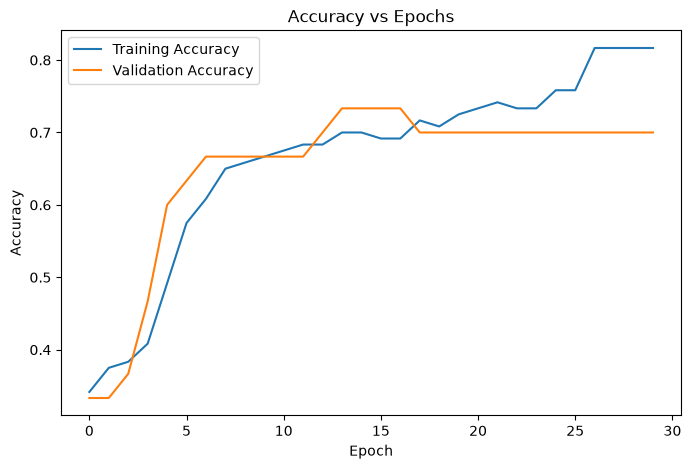

In [21]:
# Accuracy Graph

plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epochs")
plt.legend()
plt.show()

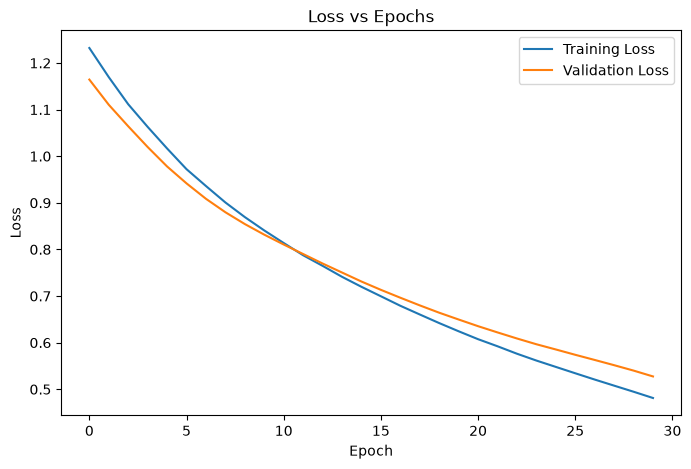

In [22]:
# Loss Graph

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epochs")
plt.legend()
plt.show()